<a href="https://colab.research.google.com/github/sharattt-H/DAV/blob/colab-integration/dav7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()

Saving housing_clean.csv to housing_clean.csv


In [ ]:
df = pd.read_csv('housing_clean.csv')
df.head()

,Area,Rooms,Age,Location_Score,Price
0,778,1,6,3,5081030
1,2148,4,27,8,11863210
2,1909,3,3,5,11371453
3,1478,3,16,3,9079771
4,1466,3,14,4,7502204


In [ ]:
from IPython.utils.syspathcontext import prepended_to_syspath
x_simple = df[['Area']]
y = df['Price']
x_tr, x_te, y_tr, y_te = train_test_split(x_simple, y, test_size=0.2, random_state=42)
model_simple = LinearRegression()
model_simple.fit(x_tr, y_tr)
pred_simple = model_simple.predict(x_te)
print('SIMPLE REGRESSION')
print('R²:',round(r2_score(y_te, pred_simple),3))
print('RMSE:',round(np.sqrt(mean_squared_error(y_te, pred_simple)),2))


SIMPLE REGRESSION
R²: 0.939
RMSE: 809207.7


In [ ]:
X_multi = df[["Area", "Rooms", "Age", "Location_Score"]]
y = df['Price']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

y_pred_multi = model_multi.predict(X_test_m)
mse_multi = mean_squared_error(y_test_m, y_pred_multi)
r2_multi = r2_score(y_test_m, y_pred_multi)

print("Multiple Linear Regression")
print(f"Root Mean Squared Error (MSE): {round(np.sqrt(mse_multi), 3)}")
print(f"R-squared (R2): {round(r2_multi, 3)}")

Multiple Linear Regression
Root Mean Squared Error (MSE): 495063.192
R-squared (R2): 0.977


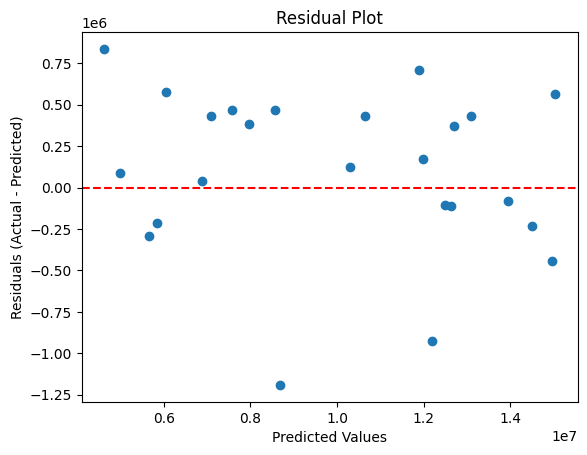

In [ ]:
residuals = y_test_m - y_pred_multi
plt.scatter(y_pred_multi, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()